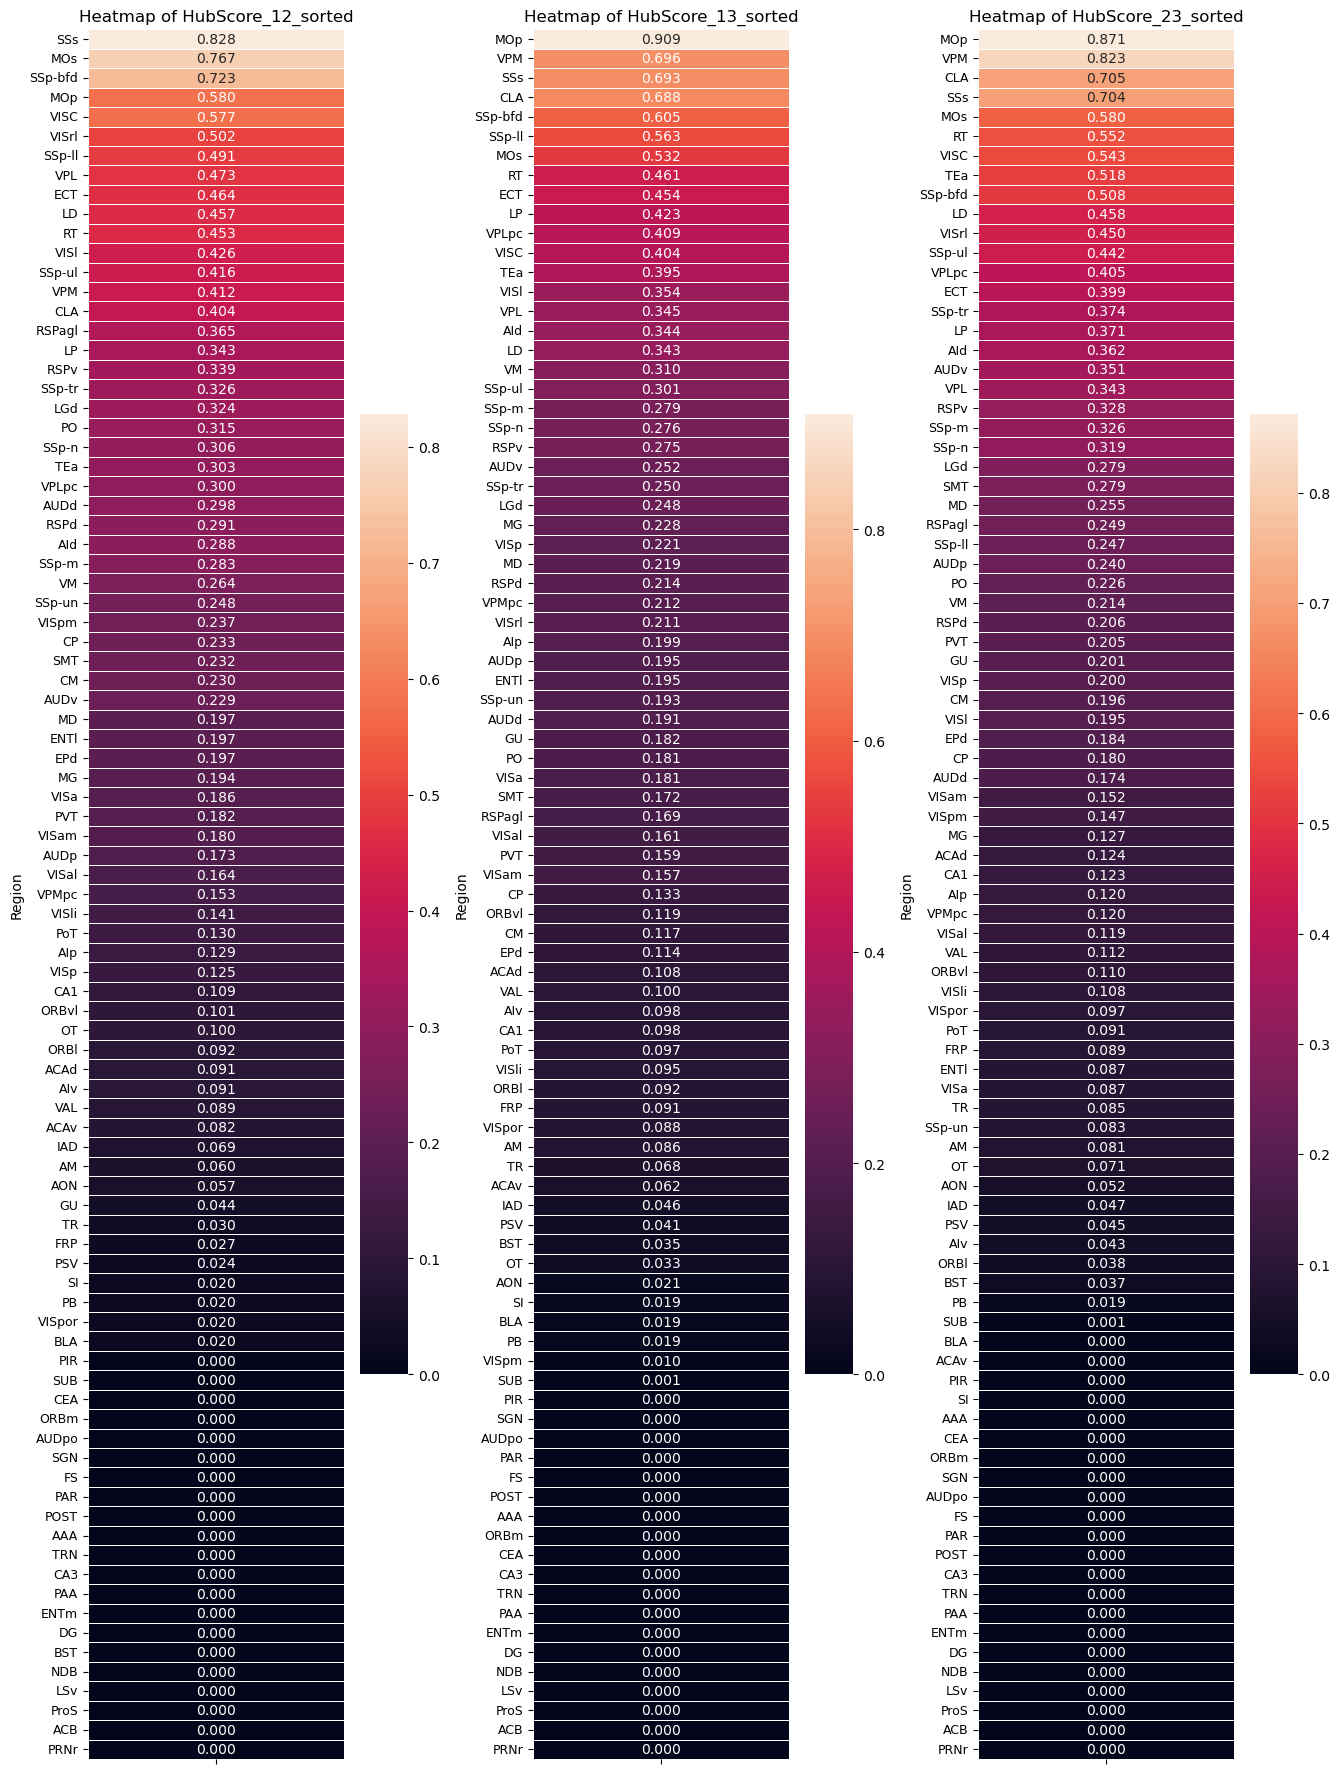

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

files = [
    "HubScore_12_sorted.csv",
    "HubScore_13_sorted.csv",
    "HubScore_23_sorted.csv"
]

valid_dfs = []
titles = []

for file in files:
    if not os.path.exists(file):
        continue
    df = pd.read_csv(file, header=None, skiprows=1, names=["Region", "Value"])
    df["Value"] = pd.to_numeric(df["Value"], errors="coerce")
    df = df.dropna(subset=["Value"])
    valid_dfs.append(df.set_index("Region")[["Value"]])
    titles.append(file.replace(".csv", ""))

if not valid_dfs:
    raise FileNotFoundError("None of the specified CSV files exist in the current directory.")

n_plots = len(valid_dfs)
fig, axes = plt.subplots(1, n_plots, figsize=(4.5 * n_plots, 0.2 * max(len(df) for df in valid_dfs)))
if n_plots == 1:
    axes = [axes]

for ax, data, title in zip(axes, valid_dfs, titles):
    sns.heatmap(
        data,
        annot=True,
        fmt=".3f",
        cmap="rocket",
        cbar=True,
        linewidths=0.5,
        square=False,
        ax=ax
    )
    ax.set_title(f"Heatmap of {title}", fontsize=12)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=9)
    ax.set_xticklabels([])

plt.tight_layout()
plt.savefig("Combined_HubScore_Heatmaps.png", dpi=300, bbox_inches="tight")
plt.show()

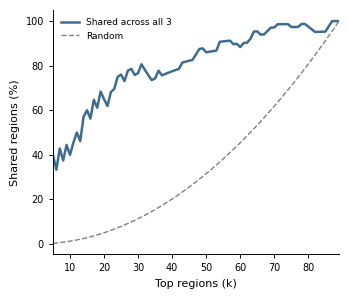

In [2]:
import pandas as pd,matplotlib.pyplot as plt

files={"II−I":"HubScore_12_sorted.csv","III−I":"HubScore_13_sorted.csv","III−II":"HubScore_23_sorted.csv"}

D={}
for k,f in files.items():
    x=pd.read_csv(f,header=None,skiprows=1,names=["Region","Value"])
    x.Value=pd.to_numeric(x.Value,errors="coerce")
    D[k]=x.dropna().sort_values("Value",ascending=False).drop_duplicates("Region")

U=set.intersection(*[set(x.Region) for x in D.values()])
D={k:x[x.Region.isin(U)].reset_index(drop=True) for k,x in D.items()}
N=len(U); K0,K1=5,min(90,N)

R=[]
for k in range(K0,K1+1):
    S=[set(x.Region[:k]) for x in D.values()]
    R.append([k,len(set.intersection(*S))/k*100,(k/N)**2*100])

res=pd.DataFrame(R,columns=["TopK","Shared","Random"])
res.to_csv("HubScore_shared_regions.csv",index=False)

plt.rcParams.update({"font.size":7,"axes.labelsize":8,
                     "xtick.labelsize":7,"ytick.labelsize":7,"axes.linewidth":.7,
                     "pdf.fonttype":42,"ps.fonttype":42})

fig,ax=plt.subplots(figsize=(3.5,3))
ax.plot(res.TopK,res.Shared,lw=1.8,color="#3F6C8E",label="Shared across all 3")
ax.plot(res.TopK,res.Random,lw=1,ls="--",color=".5",label="Random")
ax.set(xlabel="Top regions (k)",ylabel="Shared regions (%)",xlim=(K0,K1))
ax.spines[["top","right"]].set_visible(False)
ax.tick_params(width=.7,length=3)
ax.legend(frameon=False,fontsize=6.5)

plt.tight_layout()
plt.savefig("HubScore_shared_regions.pdf",bbox_inches="tight")
plt.savefig("HubScore_shared_regions.png",dpi=600,bbox_inches="tight")
plt.show()